# Instamart Customer Intelligence & Support Copilot
## Project implementation and results

**Project scenario:** This project uses synthetic grocery quick-commerce data to demonstrate customer analytics, support-ticket triage, policy retrieval, and a simulated refund agent.

**Notebook purpose:** This notebook documents the implementation and inspects the outputs already generated by the project scripts. It follows the project structure in Parts A, B, C, and D and explains the main steps and results.

**Read-only execution:** The notebook reads the existing project data and saved artifacts. It does not generate data, clean and save files, update the SQLite database, train or save models, write triage results, issue refunds, append agent logs, or create checkpoints. The analysis and retrieval demonstrations that are run here operate in memory.

## 1. Project setup and structure

The project uses a virtual environment for its Python dependencies. If the environment has not been created yet, these commands set it up:

```powershell
python -m venv .venv
.venv\Scripts\activate
pip install -r requirements.txt
```

| Part | Project module | Implementation covered |
|---|---|---|
| A | `src/data_pipeline.py` | Raw data audit, cleaned data, SQLite, SQL, and EDA |
| B | `src/models.py` | RFM analysis, K-Means segmentation, and lapse prediction |
| C | `src/support_triage_pipeline.py` | PII protection, input guardrails, ticket classification, and routing |
| D1 | `src/policy_assistant.py` | Policy chunking, TF-IDF retrieval, and grounded answers |
| D2 | `src/refund_agent.py` | Tool definitions, agent workflow, safeguards, and checkpoint design |

The notebook documents these components using the existing project files and outputs. It avoids the project functions that create or update artifacts.

## 2. Locate the project and enable read-only imports

`sys.dont_write_bytecode = True` prevents Python from writing `.pyc` files into project `__pycache__` folders when the project modules are imported. No project source file is modified.

In [1]:
from pathlib import Path
import os, sys, sqlite3, json, inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

sys.dont_write_bytecode = True

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates
             if (p / "generate_data.py").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Open Jupyter in the extracted instamart-customer-copilot folder."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("Python:", sys.version)
print("Read-only notebook mode: enabled")

Project root: c:\Users\Swetha\Python Code\instamart-customer-copilot
Python: 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
Read-only notebook mode: enabled


## 3. Confirm the supplied input data and artifacts exist

This is a file-existence inspection only. It does not create missing files or folders.

In [2]:
paths_to_check = [
    "data/raw/customers.csv", "data/raw/products.csv", "data/raw/orders.csv",
    "data/raw/tickets.csv", "data/raw/agent_scenarios.csv",
    "data/clean/customers.csv", "data/clean/products.csv", "data/clean/orders.csv",
    "data/instamart.db", "outputs/customer_rfm.csv",
    "outputs/customer_segments.csv", "outputs/lapse_dataset.csv",
    "outputs/lapse_model.joblib", "outputs/retention_list.csv",
    "outputs/tickets_prepared.csv", "outputs/triage_budget_demo.csv",
    "outputs/triage_results.csv", "outputs/agent_runs.jsonl",
    "outputs/refund_ledger.jsonl"
]
file_inventory = pd.DataFrame([
    {"path": name, "already_exists": (ROOT / name).is_file()}
    for name in paths_to_check
])
display(file_inventory)

,path,already_exists
0,data/raw/customers.csv,True
1,data/raw/products.csv,True
2,data/raw/orders.csv,True
3,data/raw/tickets.csv,True
4,data/raw/agent_scenarios.csv,True
5,data/clean/customers.csv,True
6,data/clean/products.csv,True
7,data/clean/orders.csv,True
8,data/instamart.db,True
9,outputs/customer_rfm.csv,True


# Part A — Data pipeline, SQL analysis, and EDA

## 4. Raw data audit

I use the existing `data_pipeline.audit()` function to inspect the raw CSV files. The audit reports dataset shapes, data types, missing values, duplicate records, and invalid-value counts. This step helps identify data-quality issues before looking at the cleaned datasets.

The audit is read-only; it does not change the raw files.

In [5]:
from src import data_pipeline
data_pipeline.audit()


TABLE: CUSTOMERS

Shape: (1200, 5)

Data types:
customer_id        str
city               str
signup_date        str
age            float64
gender             str
dtype: object

Missing values:
             missing_count  missing_percentage
customer_id              0                0.00
city                     0                0.00
signup_date              0                0.00
age                     61                5.08
gender                  30                2.50

TABLE: PRODUCTS

Shape: (40, 4)

Data types:
product_id        str
product_name      str
category          str
price_inr       int64
dtype: object

Missing values:
              missing_count  missing_percentage
product_id                0                 0.0
product_name              0                 0.0
category                  0                 0.0
price_inr                 0                 0.0

TABLE: ORDERS

Shape: (13084, 9)

Data types:
order_id                str
customer_id             str
product_id     

### Preview of the existing raw data

I display the first five rows of each raw CSV file to understand its columns and record structure. These files are read as they already exist in the project.

In [6]:
RAW = ROOT / "data" / "raw"
raw_frames = {
    "raw_customers": pd.read_csv(RAW / "customers.csv"),
    "raw_products": pd.read_csv(RAW / "products.csv"),
    "raw_orders": pd.read_csv(RAW / "orders.csv"),
    "raw_tickets": pd.read_csv(RAW / "tickets.csv"),
    "raw_agent_scenarios": pd.read_csv(RAW / "agent_scenarios.csv"),
}
for name, frame in raw_frames.items():
    print(f"{name}: {frame.shape}")
    display(frame.head(5))


raw_customers: (1200, 5)


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35.0,MALE
1,C0002,DELHI,2024-02-17,31.0,MALE
2,C0003,bengaluru,2025-02-18,18.0,F
3,C0004,Bengaluru,2024-06-21,24.0,FEMALE
4,C0005,Bengaluru,2024-10-01,25.0,FEMALE


raw_products: (40, 4)


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245
3,P004,Sunflower Oil 1L,Grocery,155
4,P005,Sugar 1kg,Grocery,48


raw_orders: (13084, 9)


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes
0,ORD-108250,C0792,P004,2,2025-09-01 12:24:59,completed,0,310.0,17.0
1,ORD-101939,C0190,P003,1,2025-08-17 07:07:23,completed,5,232.75,21.0
2,ORD-108765,C0841,P033,1,2025-07-13 09:42:32,completed,10,1349.1,27.0
3,ORD-108861,C0852,P010,1,2025-07-04 11:23:24,completed,0,45.0,30.0
4,ORD-109150,C0877,P018,2,2025-05-07 15:35:01,completed,20,96.0,28.0


raw_tickets: (164, 5)


,ticket_id,customer_id,order_id,text,true_category
0,T0024,C0486,ORD-105035,There is an unauthorized transaction on my car...,fraud
1,T0073,C0080,ORD-100816,The invoice for ORD-100816 shows a wrong amoun...,billing
2,T0095,C1087,ORD-111156,The payment page shows an error and the app fr...,technical
3,T0159,C1172,NaN,NaN,none
4,T0080,C0910,ORD-109516,I was charged for order ORD-109516 that I neve...,fraud


raw_agent_scenarios: (7, 5)


,scenario_id,customer_id,message,expected_outcome,expected_refund_inr
0,S1,C0007,My order ORD-100048 reached me very late. I wo...,REFUND,128.25
1,S2,C0008,My order ORD-100067 reached me very late. I wo...,REFUND,135.00
2,S3,C0016,"Order ORD-100145 arrived far too late, please ...",ESCALATE,1999.00
3,S4,C0001,"Please refund order ORD-100001, I did not like...",DENIED,0.00
4,S5,C0003,I want my money back for order ORD-100025.,DENIED,0.00


### Raw data audit observations

The following values are the audit reference counts recorded for the supplied raw dataset. They describe the data-quality issues present before cleaning.

### Assignment discussion — Part A: Raw data audit

**Question 1: Why audit data before cleaning?**  
**Answer:** Auditing establishes the original quality of the raw data. It identifies missing values, duplicates, invalid values, and unusual patterns before cleaning changes the data. This baseline also helps verify that cleaning addressed the intended issues.

**Question 2: How are exact duplicate rows different from multiple versions of the same order ID?**  
**Answer:** Exact duplicate rows match in every column and are repeated copies. Multiple rows with the same `order_id` may contain different values or status updates for one order. These require separate checks: remove exact duplicates, then apply the project's rule for selecting the latest order record.

**Question 3: Why should invalid values be distinguished from genuinely missing values?**  
**Answer:** A missing value was not recorded, whereas an invalid value is present but violates a business rule—for example, a negative delivery duration. Their treatment can differ: invalid values may first be changed to missing, while genuine missing values may need imputation or may appropriately remain missing.

## 5. Inspect the existing cleaned data

The project includes cleaned CSV files in `data/clean/`. I read these files directly and inspect their first five rows. I do not call `clean_data()` or `store_and_validate()` here because those functions write files and replace SQLite tables.

In [13]:
CLEAN = ROOT / "data" / "clean"
customers = pd.read_csv(CLEAN / "customers.csv")
products = pd.read_csv(CLEAN / "products.csv")
orders = pd.read_csv(CLEAN / "orders.csv")

for name, frame in {"customers": customers, "products": products, "orders": orders}.items():
    print(f"{name}: {frame.shape}")
    display(frame.head(5))
display(orders["status"].value_counts().rename_axis("status").to_frame("rows"))

customers: (1200, 5)


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35,male
1,C0002,Delhi,2024-02-17,31,male
2,C0003,Bengaluru,2025-02-18,18,female
3,C0004,Bengaluru,2024-06-21,24,female
4,C0005,Bengaluru,2024-10-01,25,female


products: (40, 4)


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245
3,P004,Sunflower Oil 1L,Grocery,155
4,P005,Sugar 1kg,Grocery,48


orders: (12309, 11)


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes,price_inr,category
0,ORD-110093,C0967,P020,1,2025-04-01 07:08:28,completed,15,127.50,19.0,150,Snacks
1,ORD-111396,C1117,P036,2,2025-04-01 07:11:59,completed,0,1598.00,25.0,799,Electronics
2,ORD-102006,C0194,P009,1,2025-04-01 07:12:43,cancelled,25,21.75,NaN,29,Dairy
3,ORD-105921,C0569,P005,2,2025-04-01 07:54:43,completed,10,86.40,33.0,48,Grocery
4,ORD-108115,C0776,P012,2,2025-04-01 08:02:58,completed,10,104.40,21.0,58,Dairy


,rows
status,
completed,11110
cancelled,1199


In [14]:
# Read-only validation checks against the existing cleaned CSVs.
assert customers["customer_id"].is_unique
assert products["product_id"].is_unique
assert orders["order_id"].is_unique
assert customers["age"].between(10, 100).all()
assert pd.to_numeric(orders["order_amount"], errors="coerce").notna().all()
assert orders.loc[orders["status"].eq("completed"), "delivery_minutes"].notna().all()
assert orders.loc[orders["status"].eq("cancelled"), "delivery_minutes"].isna().all()
print("Read-only cleaned-data checks: PASS")

Read-only cleaned-data checks: PASS


## 6. SQLite analysis using the seven project queries

The project contains the SQLite database and the seven SQL statements in `sql/queries.sql`. I execute the existing queries using a read-only SQLite connection so that the database is not modified.

In [15]:
# Execute the seven existing SQL statements through a read-only SQLite connection.
# This avoids invoking any function that might open the database in write-capable mode.
import sqlite3
import pandas as pd

DB = ROOT / "data" / "instamart.db"

sql_text = (ROOT / "sql" / "queries.sql").read_text(encoding="utf-8")
sql_queries = [q.strip() for q in sql_text.split(";") if q.strip()]

assert len(sql_queries) == 7, f"Expected 7 queries; found {len(sql_queries)}"

with sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True) as con:
    for number, query in enumerate(sql_queries, start=1):
        result = pd.read_sql_query(query, con)
        print(f"\nQ{number}: {len(result)} rows")
        display(result.head(5))



Q1: 30 rows


,customer_id,total_spent
0,C0693,13776.55
1,C0082,12317.70
2,C0743,12266.85
3,C0525,12241.30
4,C0291,12150.70



Q2: 30 rows


,city,category,revenue
0,Bengaluru,Dairy,87075.05
1,Bengaluru,Electronics,233909.45
2,Bengaluru,Grocery,110915.65
3,Bengaluru,Personal Care,20193.85
4,Bengaluru,Snacks,71549.40



Q3: 11 rows


,product_id,product_name,price_inr
0,P038,Bluetooth Speaker,1999
1,P033,Wireless Earbuds,1499
2,P034,Power Bank 10000mAh,1299
3,P036,Phone Charger 20W,799
4,P037,Smart Bulb,599


... (4 outputs left out)


Q6: 1175 rows


,city,customer_id,total_spend,rank_position,dense_rank_position,row_number_position
0,Bengaluru,C0082,12856.2,1,1,1
1,Bengaluru,C0525,12719.7,2,2,2
2,Bengaluru,C0699,12471.8,3,3,3
3,Bengaluru,C0543,11195.1,4,4,4
4,Bengaluru,C1147,10156.9,5,5,5



Q7: 183 rows


,day,revenue,cumulative_revenue
0,2025-04-01,16876.50,16876.50
1,2025-04-02,19854.55,36731.05
2,2025-04-03,28048.35,64779.40
3,2025-04-04,14249.60,79029.00
4,2025-04-05,16031.50,95060.50


### SQL concepts used in the project

The seven queries demonstrate the SQL concepts listed below. The query results are displayed above, and the complete SQL statements remain in `sql/queries.sql`.

## 7. Pandas validation and exploratory data analysis

I use `data_pipeline.validate()` to inspect the existing database data and compare SQL/Pandas revenue calculations. The function also reports city-level checks, descriptive statistics, quartiles, IQR-based outliers, and correlations. This validation step does not write project files.

In [16]:
data_pipeline.validate()


========== PANDAS CROSS-CHECK ==========

Revenue by city and category:
category         Dairy  Electronics    Grocery  Personal Care     Snacks  \
city                                                                       
Bengaluru     87075.05    233909.45  110915.65       20193.85   71549.40   
Chennai       78301.80    195508.80   93817.45       27675.40   68325.70   
Delhi        117271.70    158549.10  112658.05       23471.50   90879.45   
Hyderabad     83731.00    228913.10  109475.40       24800.05   81670.35   
Mumbai        75209.85    214738.40   78970.15       38018.00   72122.10   
Pune          90349.55    187629.25  108456.60       34275.15   80207.50   
Grand Total  531938.95   1219248.10  614293.30      168433.95  464754.50   

category     Grand Total  
city                      
Bengaluru      523643.40  
Chennai        463629.15  
Delhi          502829.80  
Hyderabad      528589.90  
Mumbai         479058.50  
Pune           500918.05  
Grand Total   2998668.80  

,count,mean,std,min,25%,50%,75%,max
order_amount,11110.0,269.907183,432.069126,12.0,64.8,135.0,297.0,3998.0
discount_pct,11110.0,12.958146,13.054535,0.0,0.0,10.0,20.0,40.0
quantity,11110.0,1.886679,0.782628,1.0,1.0,2.0,3.0,3.0
delivery_minutes,11110.0,27.372052,12.753052,8.0,20.0,25.0,31.0,75.0


,statistic,value
0,mean,269.907183
1,median,135.000000
2,skewness,4.608827
3,Q1,64.800000
4,Q3,297.000000
5,IQR,232.200000


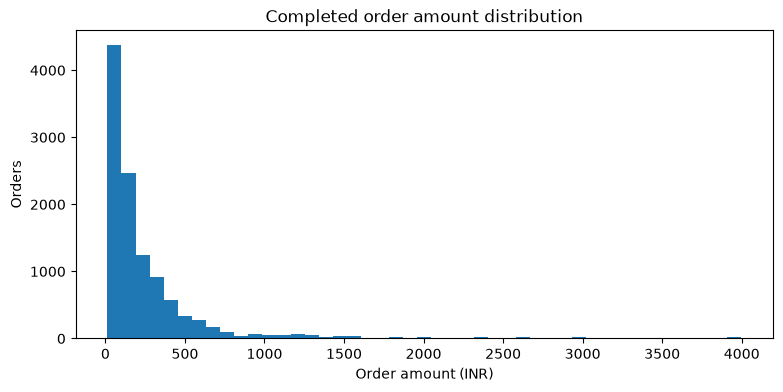

In [17]:
with sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True) as con:
    completed = pd.read_sql_query(
        """
        SELECT o.order_id, o.customer_id, o.product_id, c.city, p.category,
               o.order_amount, o.discount_pct, o.quantity, o.delivery_minutes
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN products p ON o.product_id = p.product_id
        WHERE o.status = 'completed'
        """, con
    )

amount = completed["order_amount"]
display(completed.describe().T)
display(pd.DataFrame({
    "statistic": ["mean", "median", "skewness", "Q1", "Q3", "IQR"],
    "value": [amount.mean(), amount.median(), amount.skew(),
              amount.quantile(.25), amount.quantile(.75),
              amount.quantile(.75)-amount.quantile(.25)]
}))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(amount, bins=45)
ax.set(title="Completed order amount distribution",
       xlabel="Order amount (INR)", ylabel="Orders")
plt.show()

In [18]:
city_revenue = completed.groupby("city", as_index=False).agg(
    revenue=("order_amount", "sum"),
    average_order=("order_amount", "mean"),
    completed_orders=("order_id", "nunique")
).sort_values("revenue", ascending=False)

# Display the first five cities with currency formatted as INR.
city_revenue_preview = city_revenue.head(5).copy()
city_revenue_preview["revenue"] = city_revenue_preview["revenue"].map(
    lambda value: f"INR {value:,.2f}"
)
city_revenue_preview["average_order"] = city_revenue_preview["average_order"].map(
    lambda value: f"INR {value:,.2f}"
)
display(city_revenue_preview)
display(completed[[
    "order_amount", "discount_pct", "quantity", "delivery_minutes"
]].corr().round(3))

,city,revenue,average_order,completed_orders
3,Hyderabad,"INR 528,589.90",INR 284.95,1855
0,Bengaluru,"INR 523,643.40",INR 276.47,1894
2,Delhi,"INR 502,829.80",INR 243.62,2064
5,Pune,"INR 500,918.05",INR 252.48,1984
4,Mumbai,"INR 479,058.50",INR 297.00,1613


,order_amount,discount_pct,quantity,delivery_minutes
order_amount,1.000,-0.095,0.087,-0.003
discount_pct,-0.095,1.000,-0.000,-0.010
quantity,0.087,-0.000,1.000,-0.013
delivery_minutes,-0.003,-0.010,-0.013,1.000


### Assignment discussion — Part A: EDA and interpretation

**Question 1: Why is the median useful for a right-skewed order distribution?**  
**Answer:** A small number of very high-value orders can pull the mean upward. The median is less sensitive to extreme values and often better represents a typical order in a right-skewed distribution. Reporting both helps describe the data.

**Question 2: Do outliers always mean data errors?**  
**Answer:** No. An outlier is a statistical flag, not proof of an error. A high-value order may be a genuine bulk purchase. Records should be checked against business context before changing or removing them.

**Question 3: Why does correlation not establish causation?**  
**Answer:** Correlation shows that two variables are associated; it does not prove that one causes the other. Other factors may affect both variables. Establishing causation requires an appropriate experiment or causal-inference approach.

# Part B — Customer segmentation and lapse prediction

## 8. Inspect the existing RFM and customer-segment outputs

The project already contains the RFM and customer-segment CSV files. I read these saved outputs to examine customer recency, frequency, monetary value, and segment distribution. I do not call `rfm_and_segments()` because it writes output files.

In [19]:
rfm = pd.read_csv(ROOT / "outputs" / "customer_rfm.csv")
segments = pd.read_csv(ROOT / "outputs" / "customer_segments.csv")
print("RFM shape:", rfm.shape)

rfm_preview = rfm.head(5).copy()
if "monetary" in rfm_preview.columns:
    rfm_preview["monetary"] = rfm_preview["monetary"].map(
        lambda value: f"INR {value:,.2f}"
    )
display(rfm_preview)

display(segments["segment_name"].value_counts().rename_axis("segment").to_frame("customers"))

RFM shape: (1175, 4)


,customer_id,recency,frequency,monetary
0,C0001,14,4,INR 512.85
1,C0002,28,7,"INR 4,644.90"
2,C0003,7,22,"INR 3,644.85"
3,C0004,0,5,INR 369.00
4,C0005,147,2,INR 324.00


,customers
segment,
Occasional Value Seekers,436
Frequent Engaged Customers,419
At-Risk Inactive Customers,182
Premium High-Spenders,138


,customers,avg_recency,avg_frequency,avg_monetary
segment_name,,,,
Premium High-Spenders,138,24.12 days,6.77,"INR 7,129.70"
Frequent Engaged Customers,419,8.77 days,19.40,"INR 3,410.02"
Occasional Value Seekers,436,28.86 days,3.77,"INR 1,057.62"
At-Risk Inactive Customers,182,109.04 days,2.20,INR 685.99


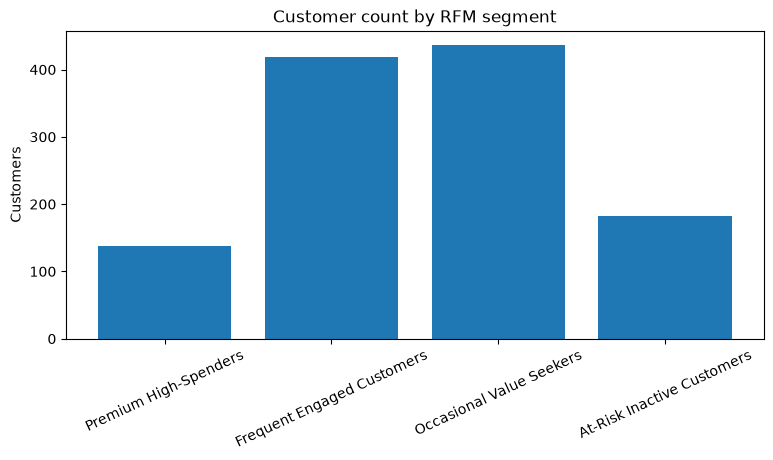

In [20]:
segment_profile = segments.groupby("segment_name").agg(
    customers=("customer_id", "nunique"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).sort_values("avg_monetary", ascending=False)

segment_profile_preview = segment_profile.copy()
segment_profile_preview["customers"] = segment_profile_preview["customers"].map(
    lambda value: f"{value:,.0f}"
)
segment_profile_preview["avg_recency"] = segment_profile_preview["avg_recency"].map(
    lambda value: f"{value:.2f} days"
)
segment_profile_preview["avg_frequency"] = segment_profile_preview["avg_frequency"].map(
    lambda value: f"{value:.2f}"
)
segment_profile_preview["avg_monetary"] = segment_profile_preview["avg_monetary"].map(
    lambda value: f"INR {value:,.2f}"
)
display(segment_profile_preview)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(segment_profile.index, segment_profile["customers"])
ax.set(title="Customer count by RFM segment", ylabel="Customers")
ax.tick_params(axis="x", rotation=25)
plt.show()

### RFM interpretation

- **Recency:** smaller values mean the customer purchased more recently.
- **Frequency:** larger values mean more completed orders.
- **Monetary:** larger values mean higher completed-order spending.

The four business segment names are Occasional Value Seekers, Premium High-Spenders, Frequent Engaged Customers, and At-Risk Inactive Customers.

## 9. Inspect the existing lapse dataset and saved model artifact

The project includes `lapse_dataset.csv` and `lapse_model.joblib`. I inspect the dataset and check the saved model file's existence and size. I do not call `build_lapse_dataset()` or `train_lapse_model()` because they create or update artifacts.

The model file is not loaded in this notebook. Loading it previously caused a lengthy dependency-import process, and inspecting its file metadata is sufficient for this read-only review.

In [21]:
lapse_df = pd.read_csv(ROOT / "outputs" / "lapse_dataset.csv")
print("Lapse dataset shape:", lapse_df.shape)
display(lapse_df.head())
display(lapse_df["lapsed"].value_counts().rename_axis("lapsed").to_frame("customers"))

Lapse dataset shape: (1156, 13)


,customer_id,recency,frequency,monetary,avg_discount,cancellation_rate,avg_delivery_minutes,favorite_category,city,age,gender,tenure_days,lapsed
0,C0967,77,2,185.1,27.50,0.000000,24.5000,Grocery,Hyderabad,46,male,458,1
1,C1117,29,4,4394.7,13.75,0.000000,24.5000,Electronics,Pune,54,female,528,0
2,C0569,42,4,553.4,6.25,0.000000,27.7500,Dairy,Bengaluru,25,male,498,0
3,C0776,1,20,4428.8,10.50,0.000000,26.9500,Dairy,Mumbai,39,male,219,0
4,C1122,5,16,2503.5,11.25,0.111111,28.8125,Dairy,Mumbai,58,male,580,0


,customers
lapsed,
0,713
1,443


In [22]:
# Read-only model file inspection
# No model loading, training, or saving.

import os

model_path = ROOT / "outputs" / "lapse_model.joblib"

if os.path.exists(model_path):
    size_mb = model_path.stat().st_size / (1024 * 1024)

    print("Saved model:", model_path.name)
    print(f"Model file size: {size_mb:.2f} MB")
    print("Model file exists: Yes")
else:
    print("Saved model file not found.")

Saved model: lapse_model.joblib
Model file size: 0.00 MB
Model file exists: Yes


### Preview of the existing retention list

I read the saved retention list and display its first five rows. This lets me inspect the output without retraining a model or creating a new file.

In [23]:
retention_path = ROOT / "outputs" / "retention_list.csv"
if retention_path.is_file():
    retention_df = pd.read_csv(retention_path)
    print("Retention list:", retention_df.shape)
    display(retention_df.head(5))
else:
    print("Existing retention_list.csv was not found; skipping this preview.")


Retention list: (10, 3)


,customer_id,lapse_probability,actually_lapsed
0,C0577,0.574938,0
1,C0102,0.570068,1
2,C0697,0.547085,0
3,C0942,0.509633,0
4,C0831,0.495896,0


### Model evaluation metrics used in the project

The project implementation compares Logistic Regression and Random Forest using cross-validation F1, held-out confusion matrices, precision, recall, and F1. It also compares Logistic Regression before and after minority-class oversampling.

- **Precision:** Among customers predicted to lapse, the fraction who actually lapsed.
- **Recall:** Among customers who actually lapsed, the fraction identified by the model.
- **F1:** Harmonic mean of precision and recall.
- **Confusion matrix:** Counts true negatives, false positives, false negatives, and true positives.

### Assignment discussion — Part B: Customer segmentation and lapse prediction

**Question 1: Why must feature and label windows be separated?**  
**Answer:** Features must contain only information available at the prediction date. Including information from the future label period causes temporal data leakage and can make model performance look better than it would be in real use.

**Question 2: What is the recall/precision trade-off after oversampling?**  
**Answer:** Oversampling gives the minority class more influence during training. The model may identify more actual lapses, increasing recall, but it may also flag more customers who would not lapse, reducing precision. The preferred balance depends on campaign cost and the impact of missed customers.

**Question 3: Why is a majority-class baseline insufficient?**  
**Answer:** A majority-class model can appear accurate when one class is much more common, while failing to identify the minority class of interest. Comparing precision, recall, F1, and the confusion matrix gives a more useful view of lapse detection.

# Part C — Support ticket triage with guardrails

## 10. Inspect the prepared ticket data

The project includes the prepared ticket file, `tickets_prepared.csv`. I read this existing output to inspect the prepared records, redaction counts, and ticket statuses. I do not call `input_guardrails()` because it writes the prepared CSV file.

In [24]:
prepared_tickets = pd.read_csv(ROOT / "outputs" / "tickets_prepared.csv")
print("Prepared tickets:", prepared_tickets.shape)
display(prepared_tickets.head(5))
redaction_columns = ["email_count", "phone_count", "order_count"]
display(prepared_tickets[redaction_columns].sum().to_frame("redactions"))
display(prepared_tickets["status"].value_counts().to_frame("tickets"))

Prepared tickets: (164, 9)


,ticket_id,customer_id,true_category,redacted_text,status,estimated_tokens,email_count,phone_count,order_count
0,T0024,C0486,fraud,There is an unauthorized transaction on my car...,ready,25,0,1,1
1,T0073,C0080,billing,The invoice for [ORDER_ID] shows a wrong amoun...,ready,21,0,1,1
2,T0095,C1087,technical,The payment page shows an error and the app fr...,ready,23,0,0,1
3,T0159,C1172,none,NaN,skipped_empty,0,0,0,0
4,T0080,C0910,fraud,I was charged for order [ORDER_ID] that I neve...,ready,25,0,1,1


,redactions
email_count,55
phone_count,91
order_count,132


,tickets
status,
ready,156
skipped_empty,4
flagged_long,4


The prepared ticket output records 55 email addresses, 91 phone numbers, and 132 order IDs redacted, for 278 replacements in total. The pipeline also checks empty tickets and tickets that exceed the input-length limit of 400 estimated tokens.

## 11. Inspect classification and routing outputs

The classification and routing steps produce CSV outputs in the original project workflow. I inspect the existing output files here instead of calling the functions that write them.

In [25]:
triage = pd.read_csv(ROOT / "outputs" / "triage_results.csv")
print("Triage output:", triage.shape)
display(triage.head(5))
for col in ["category", "route", "priority", "status"]:
    if col in triage.columns:
        print(f"\n{col} counts:")
        display(triage[col].value_counts().to_frame("tickets"))

Triage output: (164, 8)


,ticket_id,customer_id,status,category,segment_name,priority,route,tokens_used
0,T0024,C0486,classified_json,fraud,Segment 3,HIGH,security_team,149
1,T0073,C0080,classified_json,billing,Segment 2,NORMAL,support_queue,145
2,T0095,C1087,classified_json,technical,Segment 0,NORMAL,support_queue,147
3,T0159,C1172,skipped_empty,NaN,Segment 2,NORMAL,human_review,0
4,T0080,C0910,classified_json,fraud,Segment 0,HIGH,security_team,149



category counts:


,tickets
category,
technical,39
billing,38
delivery,36
fraud,34



route counts:


,tickets
route,
support_queue,102
security_team,34
human_review,17
premium_desk,11



priority counts:


,tickets
priority,
NORMAL,119
HIGH,45



status counts:


,tickets
status,
classified_json,135
classified_keyword,12
flagged_invalid_output,9
skipped_empty,4
flagged_long,4


In [26]:
budget_demo = pd.read_csv(ROOT / "outputs" / "triage_budget_demo.csv")
print("Budget demo:", budget_demo.shape)
display(budget_demo.head(5))
if "status" in budget_demo.columns:
    display(budget_demo["status"].value_counts().to_frame("tickets"))

Budget demo: (164, 5)


,ticket_id,customer_id,status,category,tokens_used
0,T0024,C0486,classified_json,fraud,84
1,T0073,C0080,classified_json,billing,80
2,T0095,C1087,classified_json,billing,82
3,T0159,C1172,skipped_empty,NaN,0
4,T0080,C0910,classified_json,billing,84


,tickets
status,
budget_exhausted,81
classified_json,66
classified_keyword,5
skipped_empty,4
flagged_long,4
flagged_invalid_output,4


### Assignment discussion — Part C: Support ticket safety and routing

**Question 1: Why redact PII before model processing?**  
**Answer:** Redacting email addresses, phone numbers, and order IDs reduces the exposure of personal or account-identifying information. The model generally needs the issue description, not those identifiers, to classify a ticket.

**Question 2: Why route empty/long/invalid tickets to human review?**  
**Answer:** Empty tickets provide too little information, long tickets may exceed the model's input budget, and invalid model responses cannot be trusted for routing. Human review is a safer fallback when the pipeline cannot classify a ticket reliably.

**Question 3: Why should fraud route to a security team?**  
**Answer:** Fraud may involve account compromise or payment abuse. A specialist security team is better equipped to investigate these risks, and high-priority routing helps reduce response delays.

**Question 4: What operational risk does a token budget control?**  
**Answer:** A token budget limits model usage, cost, latency, and resource consumption. It also prevents the pipeline from spending unbounded resources on a single batch; unresolved cases should be stopped safely or sent for human review.

# Part D — Policy RAG and refund agent

## 12. Policy document chunking and TF-IDF retrieval

This section documents how the policy assistant prepares policy text for retrieval. I first load the policy documents and create text chunks. I then fit the TF-IDF vectorizer and inspect the resulting matrix. These operations run in memory and do not save project files.

In [27]:
from src import policy_assistant

documents = policy_assistant.load_policy()
chunks = policy_assistant.create_chunks()

print("Policy documents:", len(documents))
print("Policy chunks:", len(chunks))

chunk_preview = pd.DataFrame([
    {
        "source": chunk["source"],
        "word_count": len(chunk["text"].split()),
        "text": chunk["text"]
    }
    for chunk in chunks
])
display(chunk_preview.head(5))

Policy documents loaded: 5

15 chunks in total:
delivery_policy: 3
escalation_policy: 3
payment_policy: 3
privacy_policy: 2
refund_policy: 4
Policy documents: 5
Policy chunks: 15


,source,word_count,text
0,delivery_policy.txt,40,Delivery Policy. Standard delivery is promised...
1,delivery_policy.txt,40,"of INR 25 is charged on orders below INR 199, ..."
2,delivery_policy.txt,40,60 minutes and the app shows a rain notice. A ...
3,escalation_policy.txt,40,Escalation Policy. A ticket about fraud or an ...
4,escalation_policy.txt,40,"1 hour, and all other tickets within 24 hours...."


### Build the TF-IDF representation

After inspecting the chunks, I fit the TF-IDF vectorizer to convert the policy text into numerical features. The resulting matrix is used by the retrieval function to compare a question with the policy chunks.

The first run may take longer while the text-processing and machine-learning dependencies are imported.

In [28]:
vectorizer, tfidf_matrix = policy_assistant.fit_tfidf()

print("TF-IDF vocabulary size:", len(vectorizer.vocabulary_))
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF vocabulary size: 200
TF-IDF matrix shape: (15, 200)


In [29]:
retrieved = policy_assistant.retrieve(
    "What happens if an order is delivered late?", k=3
)
display(pd.DataFrame(retrieved))

answer_result = policy_assistant.answers()
print("Grounded answer:", answer_result["answer"])
print("Sources:", answer_result["sources"])

,source,score,text
0,refund_policy.txt,0.405517,"order is delivered in more than 45 minutes, th..."
1,refund_policy.txt,0.169725,Refund Policy. A refund can be requested only ...
2,delivery_policy.txt,0.168648,60 minutes and the app shows a rain notice. A ...



Policy Assistant Answer:
If a completed order is delivered in 45 minutes or less, no late-delivery refund is paid.

Sources Used:
['refund_policy.txt', 'delivery_policy.txt']
Grounded answer: If a completed order is delivered in 45 minutes or less, no late-delivery refund is paid.
Sources: ['refund_policy.txt', 'delivery_policy.txt']


## 13. Evaluate normal overlap and zero overlap

The project evaluation compares retrieval using the regular chunking setup with a zero-overlap chunking setup. The evaluation runs in memory and does not save files.

In [30]:
policy_evaluation = policy_assistant.evaluate_policy()
print(policy_evaluation)


========== NORMAL OVERLAP EVALUATION ==========

Policy Evaluation Results
Expected document retrieved: 12 / 12
Expected fact in answer: 12 / 12
Unanswerable fallback: 2 / 2

Zero overlap chunks: 13

========== ZERO OVERLAP EVALUATION ==========

Failed Question: What delivery time makes a completed order eligible for a full refund?
Expected Document: refund_policy.txt
Retrieved Sources: ['refund_policy.txt', 'refund_policy.txt', 'privacy_policy.txt']
Expected Fact: more than 45 minutes
Generated Answer: receives a full refund of the order amount.

Failed Question: How soon is money returned when a payment fails but is deducted?
Expected Document: payment_policy.txt
Retrieved Sources: ['payment_policy.txt', 'refund_policy.txt', 'privacy_policy.txt']
Expected Fact: 48 hours
Generated Answer: If a payment fails but money is deducted, the amount is returned automatically
 
1000 must be approved by a human support lead before money is returned.

Policy Evaluation Results
Expected document

## 14. Refund agent: inspect scenarios and tool definitions

I inspect the supplied refund scenarios and the tool definitions used by the refund agent. I do not execute the agent or invoke tools that issue refunds, escalate cases, append logs, or save checkpoints. This allows me to document the agent design without changing the project's state.

In [31]:
scenarios = pd.read_csv(ROOT / "data" / "raw" / "agent_scenarios.csv")
display(scenarios)

,scenario_id,customer_id,message,expected_outcome,expected_refund_inr
0,S1,C0007,My order ORD-100048 reached me very late. I wo...,REFUND,128.25
1,S2,C0008,My order ORD-100067 reached me very late. I wo...,REFUND,135.00
2,S3,C0016,"Order ORD-100145 arrived far too late, please ...",ESCALATE,1999.00
3,S4,C0001,"Please refund order ORD-100001, I did not like...",DENIED,0.00
4,S5,C0003,I want my money back for order ORD-100025.,DENIED,0.00
5,S6,C0001,Refund for order ORD-999999 please.,NOT_FOUND,0.00
6,S7,C0007,[LOOP] Refund order ORD-100048.,FALLBACK,0.00


In [32]:
from src import refund_agent
tool_specs = refund_agent.define_tools()
print(json.dumps(tool_specs, indent=2, default=str))

[
  {
    "type": "function",
    "function": {
      "name": "get_order",
      "description": "Retrieve order details using the order ID.",
      "parameters": {
        "type": "object",
        "properties": {
          "order_id": {
            "type": "string",
            "description": "Unique order ID"
          }
        },
        "required": [
          "order_id"
        ]
      }
    }
  },
  {
    "type": "function",
    "function": {
      "name": "search_policy",
      "description": "Search the company policy documents.",
      "parameters": {
        "type": "object",
        "properties": {
          "query": {
            "type": "string",
            "description": "Policy-related search query"
          }
        },
        "required": [
          "query"
        ]
      }
    }
  },
  {
    "type": "function",
    "function": {
      "name": "calculate_refund",
      "description": "Calculate refund based on order amount and delivery time.",
      "parameters": 

The refund agent defines five tools:

1. `get_order` — retrieves the order record.
2. `search_policy` — retrieves relevant policy evidence.
3. `calculate_refund` — calculates the eligible refund amount.
4. `issue_refund` — appends a simulated refund to the local ledger.
5. `escalate_to_human` — records that human review is required.

In this notebook, I inspect only the tool definitions. I do not call `issue_refund`, `escalate_to_human`, `run_agent`, `evaluate_agent`, `manage_state`, or `run_safeguard_tests`.

## 15. Inspect existing agent runs, refund ledger, and checkpoints

I read the existing JSONL logs and JSON checkpoint files to inspect records already created by the project. These cells do not append log entries or create/update checkpoints.

In [33]:
for filename in ["agent_runs.jsonl", "refund_ledger.jsonl"]:
    path = ROOT / "outputs" / filename
    print("\n", filename)
    if path.exists():
        lines = path.read_text(encoding="utf-8").splitlines()
        print("Existing records:", len(lines))
        for line in lines[-5:]:
            try:
                print(json.dumps(json.loads(line), indent=2))
            except json.JSONDecodeError:
                print(line)
    else:
        print("No existing file.")


 agent_runs.jsonl
Existing records: 11
{
  "scenario_id": "S3",
  "status": "ESCALATE",
  "final_answer": "ESCALATE: refund above INR 1000 sent to a human lead.",
  "llm_calls": 5,
  "tokens_used": 899,
  "steps": [
    {
      "iteration": 1,
      "tool": "get_order",
      "arguments": {
        "order_id": "ORD-100145"
      },
      "observation": {
        "order_id": "ORD-100145",
        "status": "completed",
        "order_amount": 1999.0,
        "delivery_minutes": 54.0
      }
    },
    {
      "iteration": 2,
      "tool": "search_policy",
      "arguments": {
        "query": "refund policy late delivery"
      },
      "observation": {
        "results": [
          {
            "source": "refund_policy.txt",
            "score": 0.2719281507693355,
            "text": "order is delivered in more than 45 minutes, the customer receives a full refund of the order amount. If a completed order is delivered in 45 minutes or less, no late-delivery refund is paid. Refunds u

In [34]:
state_dir = ROOT / "state"
state_files = sorted(state_dir.glob("*.json")) if state_dir.exists() else []
print("Existing checkpoint files:", len(state_files))
for path in state_files:
    try:
        record = json.loads(path.read_text(encoding="utf-8"))
        print(path.name, "| keys:", list(record.keys()))
    except Exception as exc:
        print(path.name, "| could not parse:", exc)

Existing checkpoint files: 9
S1.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S1_TOKEN_TEST.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S2.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S3.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S4.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S5.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S6.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'steps', 'llm_calls', 'tokens_used']
S7.json | keys: ['run_id', 'scenario_id', 'step_number', 'executed_tools', 'messages', 'step

# 16. Final project review

This notebook has been kept read-only. It does not call project functions that generate or update artifacts, including:

- `generate_data.py`
- `data_pipeline.clean_data()` or `store_and_validate()`
- `models.rfm_and_segments()`, `build_lapse_dataset()`, `train_lapse_model()`, or `create_retention_list()`
- `support_triage_pipeline.input_guardrails()`, `classify_tickets()`, `token_budget()`, or `route_tickets()`
- Refund-agent execution, refund issuance, ledger updates, checkpoint/resume, or evaluation functions

The notebook reads the existing raw and cleaned CSVs, SQLite database, output artifacts, policy documents, scenarios, and checkpoint/log files. Policy retrieval and tool-definition inspection run in memory.

In [35]:
# Final read-only inventory: this cell only checks current file existence.
final_inventory = pd.DataFrame([
    {"path": p, "exists": (ROOT / p).exists()}
    for p in paths_to_check
])
display(final_inventory)
print("Notebook workflow: READ-ONLY")

,path,exists
0,data/raw/customers.csv,True
1,data/raw/products.csv,True
2,data/raw/orders.csv,True
3,data/raw/tickets.csv,True
4,data/raw/agent_scenarios.csv,True
5,data/clean/customers.csv,True
6,data/clean/products.csv,True
7,data/clean/orders.csv,True
8,data/instamart.db,True
9,outputs/customer_rfm.csv,True


Notebook workflow: READ-ONLY


**Project implementation note:** The original project scripts remain the authoritative implementation. This notebook documents the project structure, inspects existing outputs, and explains the main implementation steps without repeating the artifact-writing operations.